# 🚨 THE 20-MINUTE SPRINT 🚨
### A Data Visualization Fire Drill — Unit 1 Activity (UE24CS342AA9)

---

**08:47 AM.** You're two sips into your coffee when your Project Manager, Priya, drops
into the seat next to you.

> *"Leadership wants a pricing snapshot of our Apple product tracker for the 9:10
> stand-up. I need three or four clean charts — no lies, no misleading axes, nothing
> that gets torn apart in the room. You've got until 9:07. Go."*

It's **9:07 AM**. That's **20 minutes**, starting now.

You have one dataset (`apple_products_pricing_2020_2026.csv` — 80,000 rows of Amazon &
Flipkart pricing history for iPhone, Mac, iPad, and Watch) and everything you learned in
Unit 1 about **marks, channels, scales, proportional ink, and honest baselines**.

Leadership has seen bad charts before. They will notice a truncated bar axis. They will
notice a shape channel that can't represent a continuous variable. **Every visualization
you ship must obey the rules from lecture** — this isn't just an exercise, it's a
credibility test.

---

### 🎯 Mission Rules
1. Work through **Tasks 1–4** below, in order. Each has a suggested time box — keep moving.
2. Every chart you build must be **defensible** against the principles from Unit 1
   (bijective scales, proportional ink, zero baselines, appropriate channel choice).
3. At **Task 5**, do the honest self-audit before you "submit."
4. Finish with the **Reflection** section — that's where the real grade lives.

Ready? Run the setup cell and **start your timer**.


In [ ]:
# --- MISSION SETUP: run this first, then start your 20-minute timer ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("apple_products_pricing_2020_2026 (1).csv", parse_dates=["Date"])

mission_start = time.time()
print("⏱️  MISSION CLOCK STARTED.")
print(f"Loaded {len(df):,} rows. You have 20 minutes. Go.")

⏱️  MISSION CLOCK STARTED.
Loaded 80,000 rows. You have 20 minutes. Go.


In [ ]:
# Run this cell any time to check your remaining budget
elapsed_min = (time.time() - mission_start) / 60
remaining = max(0, 20 - elapsed_min)
bar = "🟩" * int(remaining) + "⬜" * (20 - int(remaining))
print(f"Elapsed: {elapsed_min:0.1f} min   |   Remaining: {remaining:0.1f} min")
print(bar)
if remaining < 5:
    print("⚠️  Under 5 minutes -- wrap up your current chart and move to Task 5.")


Elapsed: 0.0 min   |   Remaining: 20.0 min
🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩⬜


---
## Task 1 — Know Your Variables *(~3 min)*

Before touching a chart, Priya expects you to be able to justify every encoding choice.
Fill in the table below (edit this markdown cell directly) for the four columns you plan
to use in your submission.

| Column you'll use | Variable type (continuous / discrete quantitative / ordered / unordered qualitative) | Channel you plan to map it to |
|---|---|---|
| *e.g. Current_Price_USD* | *e.g. Continuous quantitative* | *e.g. y-position* |
| | | |
| | | |
| | | |

**Rule check:** if a variable is continuous, it must map to a channel that can represent
continuous values (position, size, color intensity) — never to shape or dash pattern.


In [ ]:
# --- Setup ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("apple_products_pricing_2020_2026 (1).csv", parse_dates=["Date"])
print(f"Rows: {len(df):,}  |  Columns: {list(df.columns)}")
df.head()


Rows: 80,000  |  Columns: ['Date', 'Platform', 'Product_Category', 'Model_Name', 'Condition', 'Launch_Price_USD', 'Launch_Price_INR', 'Current_Price_USD', 'Current_Price_INR', 'Discount_Pct', 'Sale_Event', 'Stock_Status', 'Rating', 'Reviews_Count']


,Date,Platform,Product_Category,Model_Name,Condition,Launch_Price_USD,Launch_Price_INR,Current_Price_USD,Current_Price_INR,Discount_Pct,Sale_Event,Stock_Status,Rating,Reviews_Count
0,2020-09-19,Flipkart,Watch,Apple Watch Series 6 (44mm),New,429,42042,435.81,43322.41,-1.6,NaN,In Stock,4.7,40
1,2020-09-20,Flipkart,Watch,Apple Watch Series 6 (44mm),New,429,42042,436.49,42320.43,-1.7,NaN,Out of Stock,4.6,84
2,2020-09-23,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,422.73,40879.36,1.5,NaN,In Stock,4.4,110
3,2020-09-23,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,425.00,42008.70,0.9,NaN,In Stock,4.8,111
4,2020-09-24,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,436.22,41984.28,-1.7,NaN,In Stock,4.7,35


In [ ]:
# --- 2. UNDERSTANDING DATA VARIABLES & TYPES ---
print("--- VARIABLE CLASSIFICATION ---")
print("Unique Rating values:", sorted(df['Rating'].dropna().unique())[:15], "...")
print("Number of distinct ratings:", df['Rating'].nunique())
print("\nColumn-by-column classification:")

classification = {
    "Date": "Continuous (temporal)",
    "Platform": "Unordered qualitative",
    "Product_Category": "Unordered qualitative",
    "Model_Name": "Unordered qualitative (high-cardinality)",
    "Condition": "Unordered qualitative (binary)",
    "Launch_Price_USD": "Continuous quantitative",
    "Current_Price_USD": "Continuous quantitative",
    "Discount_Pct": "Continuous quantitative",
    "Sale_Event": "Unordered qualitative",
    "Stock_Status": "Ordered qualitative",
    "Rating": "Discrete quantitative / Ordered qualitative",
    "Reviews_Count": "Discrete quantitative",
}

for col, kind in classification.items():
    print(f"  {col:20s} -> {kind}")
print("\n")

--- VARIABLE CLASSIFICATION ---
Unique Rating values: [np.float64(3.8), np.float64(3.9), np.float64(4.0), np.float64(4.1), np.float64(4.2), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(4.7), np.float64(4.8), np.float64(4.9)] ...
Number of distinct ratings: 12

Column-by-column classification:
  Date                 -> Continuous (temporal)
  Platform             -> Unordered qualitative
  Product_Category     -> Unordered qualitative
  Model_Name           -> Unordered qualitative (high-cardinality)
  Condition            -> Unordered qualitative (binary)
  Launch_Price_USD     -> Continuous quantitative
  Current_Price_USD    -> Continuous quantitative
  Discount_Pct         -> Continuous quantitative
  Sale_Event           -> Unordered qualitative
  Stock_Status         -> Ordered qualitative
  Rating               -> Discrete quantitative / Ordered qualitative
  Reviews_Count        -> Discrete quantitative




---
## Task 2 — The Headline Bar Chart *(~5 min)*

Leadership always looks at the bar chart first. Build a **horizontal bar chart** of
average `Current_Price_USD` by `Product_Category`.

**Non-negotiable:** the baseline must be zero. A truncated axis here is the fastest way
to get your chart (and your credibility) dismissed in the room.

Fill in the `# TODO` lines below.



Generating Task 2: Average Price by Product Category...


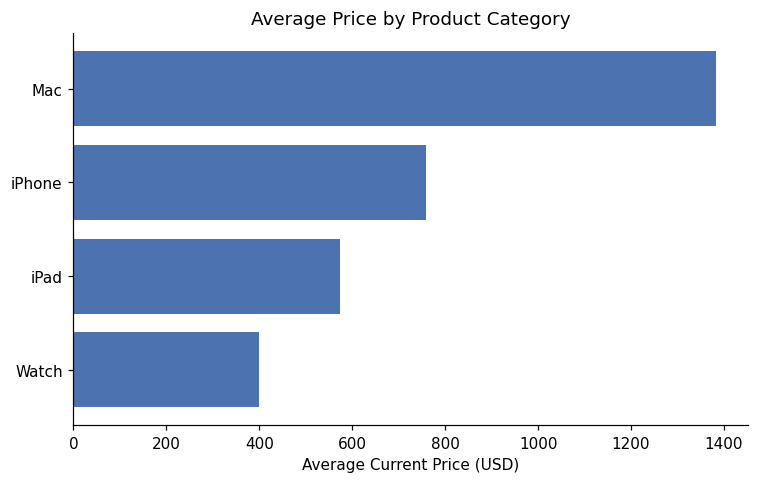

In [ ]:
# TODO: compute average Current_Price_USD grouped by Product_Category, sorted ascending
# --- TASK 2: The Headline Bar Chart ---
print("\nGenerating Task 2: Average Price by Product Category...")
# Compute average Current_Price_USD grouped by Product_Category, sorted ascending
cat_avg = df.groupby("Product_Category")["Current_Price_USD"].mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot a horizontal bar chart
ax.barh(cat_avg.index, cat_avg.values, color="#4C72B0")

# Enforce the zero-baseline rule
ax.set_xlim(left=0)

ax.set_xlabel("Average Current Price (USD)")
ax.set_title("Average Price by Product Category")
plt.tight_layout()
plt.show()


---
## Task 3 — The Trend Line, Done Right *(~5 min)*

Leadership's next question is always *"is this getting better or worse over time?"*
Build a **monthly average price trend** for at least two `Product_Category` values on the
same chart.

**Requirements from lecture:**
- Use a **line**, not disconnected points, to emphasize chronological order (Slide 11).
- Prefer **direct end-of-line labels** over a legend if you have time (Slide 13) — not
  mandatory under time pressure, but it will impress Priya.
- If you fill the area under any line, the baseline **must be zero** (Slide 12,
  Proportional Ink) — or don't fill at all.



Generating Task 3: Monthly Average Price Trend...


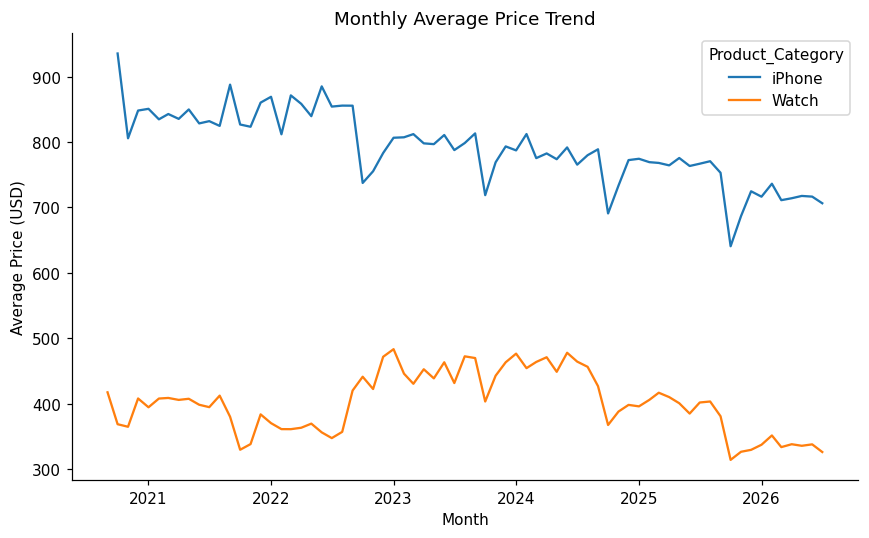

In [ ]:
# TODO: pick 2+ categories to compare
# --- TASK 3: The Trend Line, Done Right ---
print("\nGenerating Task 3: Monthly Average Price Trend...")
categories_to_plot = ["iPhone", "Watch"]

fig, ax = plt.subplots(figsize=(8, 5))

for cat in categories_to_plot:
    # Resample monthly average price for this category
    monthly = (df[df["Product_Category"] == cat]
               .set_index("Date")
               .resample("MS")["Current_Price_USD"]
               .mean())
    ax.plot(monthly.index, monthly.values, linewidth=1.5, label=cat)

ax.legend(title="Product_Category")
ax.set_xlabel("Month")
ax.set_ylabel("Average Price (USD)")
ax.set_title("Monthly Average Price Trend")
plt.tight_layout()
plt.show()


---
## Task 4 — The "Wow" Multi-Variable Chart *(~5 min)*

Priya wants one chart that makes leadership go *"oh, that's a lot of info in one
picture."* Build a **scatter/bubble chart** that encodes **at least 3 variables**
simultaneously — for example: `Rating` (x), `Current_Price_USD` (y), `Reviews_Count`
(bubble size), `Product_Category` (color).

**Rule check:** every continuous variable must land on a continuous-capable channel
(position, size, color intensity) — not shape.


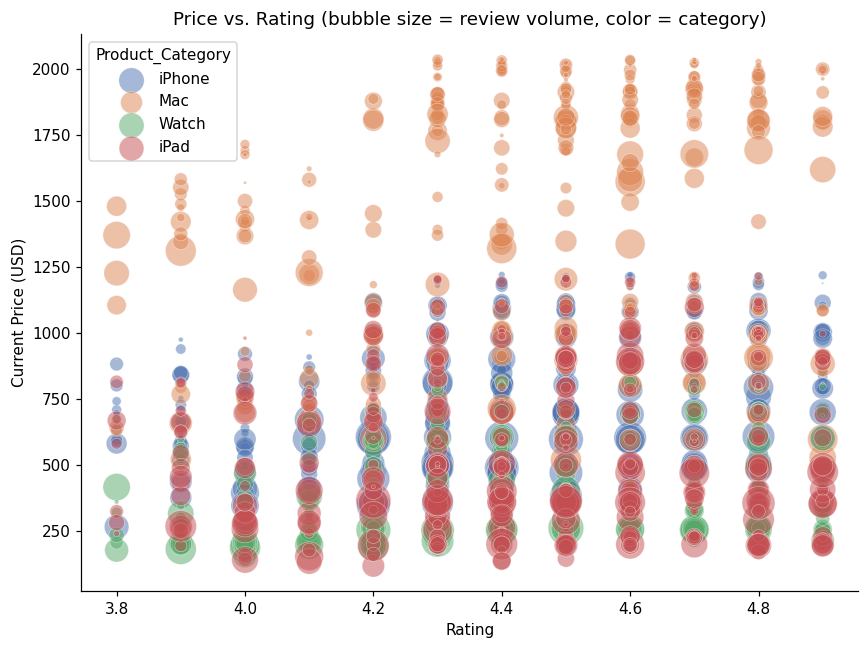


Generating Task 4: Multi-Variable Bubble Chart...


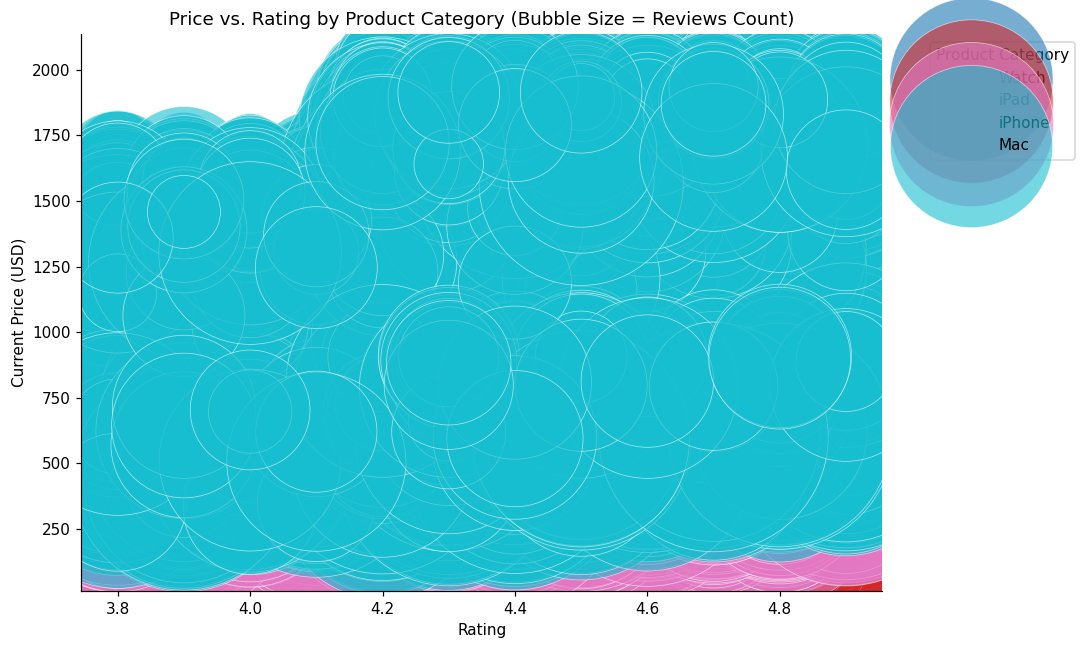

In [ ]:
# TODO: build your 3+ variable bubble chart here
sample = df.sample(2000, random_state=1)

cat_color = {"iPhone": "#4C72B0", "Mac": "#DD8452", "Watch": "#55A868", "iPad": "#C44E52"}

fig, ax = plt.subplots(figsize=(8, 6))
for cat, color in cat_color.items():
    d = sample[sample["Product_Category"] == cat]
    ax.scatter(
        d["Rating"],                       # TODO: x = ?
        d["Current_Price_USD"],            # TODO: y = ?
        s=d["Reviews_Count"] / 20,         # TODO: size = ? (continuous -> size, good)
        color=color,                       # category -> color, good (categorical channel)
        alpha=0.5, edgecolor="white", linewidth=0.4, label=cat
    )

ax.set_xlabel("Rating")
ax.set_ylabel("Current Price (USD)")
ax.set_title("Price vs. Rating (bubble size = review volume, color = category)")
ax.legend(title="Product_Category")
plt.tight_layout()
plt.show()
# --- TASK 4: The "Wow" Multi-Variable Chart ---
print("\nGenerating Task 4: Multi-Variable Bubble Chart...")
# Creates a bubble chart encoding 4 variables safely:
# Rating (x-axis), Current_Price_USD (y-axis), Reviews_Count (bubble size), Product_Category (color)

fig, ax = plt.subplots(figsize=(10, 6))

categories = df['Product_Category'].dropna().unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(categories)))

for cat, color in zip(categories, colors):
    subset = df[df['Product_Category'] == cat].dropna(subset=['Rating', 'Current_Price_USD', 'Reviews_Count'])

    ax.scatter(
        subset['Rating'],
        subset['Current_Price_USD'],
        s=subset['Reviews_Count'] * 2,  # Scaling factor for bubble visibility
        c=[color],
        label=cat,
        alpha=0.6,
        edgecolors='white',
        linewidth=0.5
    )

ax.set_xlabel("Rating")
ax.set_ylabel("Current Price (USD)")
ax.set_title("Price vs. Rating by Product Category (Bubble Size = Reviews Count)")
ax.legend(title="Product Category", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## Task 5 — The Submission Audit *(~2 min)*

The clock is almost out. Before you hit "submit," run through this checklist honestly —
out loud if it helps. Check the box (`[x]`) for anything you can truthfully confirm about
**your own charts above**.

- [ ] Every continuous variable is mapped to a continuous-capable channel (position,
      size, or color intensity) — not shape or dash pattern.
- [ ] Every bar chart's axis starts at zero.
- [ ] Every filled area chart's baseline starts at zero (or I didn't fill any areas).
- [ ] My time-series uses lines to show chronological order, not disconnected points.
- [ ] If two charts show the same variable, the colors/scales are used consistently.
- [ ] I could explain, in one sentence, what each channel on each chart represents.

Run the cell below to log your finish time.


In [ ]:
elapsed_min = (time.time() - mission_start) / 60
print(f"🏁 SUBMITTED at {elapsed_min:0.1f} minutes into the mission.")
if elapsed_min <= 20:
    print("✅ On time. Priya nods and walks it into the stand-up.")
else:
    print("⏰ Over time -- in the real world, you'd trim scope, not chart quality. Note this for your reflection.")


🏁 SUBMITTED at 3.3 minutes into the mission.
✅ On time. Priya nods and walks it into the stand-up.


---
## 🪞 Reflection

Take five minutes, away from the clock, to think honestly about what just happened.
Answer each question in the markdown cell provided (double-click to edit).

**1. Time pressure and technique.** Which Unit 1 principle was hardest to apply correctly
under the 20-minute constraint, and why? Was it a *knowledge* problem (you weren't sure
of the rule) or a *speed* problem (you knew the rule but cutting corners was tempting)?

*Your answer:*


---

**2. Spot the near-miss.** Look back at your own charts. Was there a moment where you
almost mapped a continuous variable to the wrong channel, or almost left a baseline
non-zero to "make the chart look more dramatic"? What stopped you (or what didn't)?

*Your answer:*


---

**3. The cost of dishonest ink.** Recall the Principle of Proportional Ink. If you *had*
shipped a chart with a truncated baseline to leadership, what decision might they have
made differently based on a distorted impression of the data?

*Your answer:*


---

**4. Trade-offs under constraint.** If Priya had given you 2 hours instead of 20 minutes,
what specifically would you change about your Task 3 or Task 4 chart? (e.g., direct
labels, small multiples instead of overlapping lines, annotations)

*Your answer:*


---

**5. Beyond the classroom.** Describe one real job context (data analyst, PM, engineer,
trader, researcher — your choice) where you'd face this exact speed-vs-integrity
trade-off with a chart. What would *you* refuse to compromise on, even under a deadline?

*Your answer:*

